# ⚽ La forme récente avant chaque match de Ligue des Champions

**Groupe :** Maxime, Loan, Moussa, Mouhamedou et Ousmane — partie forme : Loan

## Pourquoi ce notebook ?
L'Elo résume le niveau d'un club sur des années. La **forme récente** regarde seulement ses derniers matchs : un club peut avoir un bon Elo et traverser une mauvaise passe. On construit cette variable pour que le modèle de scores (`MODEL_POISSON.ipynb`) puisse tester si elle apporte quelque chose **en plus** de l'Elo.

## La définition (fixée avant de regarder les résultats)
- **Forme = points moyens par match** (victoire 3, nul 1, défaite 0) sur les **5 derniers matchs officiels** du club ;
- **toutes compétitions** de clubs dans `games.csv` : championnat, coupes, coupes d'Europe et leurs qualifications, supercoupes. On exclut seulement les compétitions d'équipes nationales ;
- joués **strictement avant** la date du match (pas le jour même), et **dans les 60 jours** avant : un match de mai ne dit rien de la forme en septembre ;
- moins de 5 matchs dans les 60 jours : moyenne sur ceux disponibles, et une colonne donne leur nombre. **0 match : valeur manquante (NaN)** ;
- un match **décidé aux tirs au but compte comme un nul** (correction de l'EDA, appliquée ici à toutes les compétitions).

## Ce qu'on livre
`output/forme_par_match.csv` : une ligne par match de C1 (1 871), jointure par `game_id`. Colonnes : `game_id`, `home_forme_5`, `away_forme_5`, `home_nb_matchs_forme`, `away_nb_matchs_forme`, `ecart_forme_5` (= domicile − extérieur). On ne modifie pas `eda_matchs_c1.csv` : la jointure se fait dans `MODEL_POISSON.ipynb`.

## Plan
1. Les matchs officiels et la correction des tirs au but
2. Le calcul de la forme
3. Vérification à la main sur 3 exemples
4. Contrôles automatiques et valeurs manquantes
5. La forme est-elle liée au résultat ? Et à l'Elo ?
6. Export
7. Limites et conclusion

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%config InlineBackend.figure_format = 'retina'
BLEU, ORANGE, GRIS, ENCRE = '#2a78d6', '#eb6834', '#b5b3ad', '#52514e'
N_MATCHS = 5          # on regarde les 5 derniers matchs officiels...
FENETRE_JOURS = 60    # ... joués dans les 60 jours avant le match

c1 = pd.read_csv('../output/eda_matchs_c1.csv', encoding='utf-8-sig', parse_dates=['date'],
                 usecols=['game_id', 'date', 'season', 'home_club_id', 'away_club_id', 'home_club_name',
                          'away_club_name', 'ecart_elo_complet', 'resultat'])
games = pd.read_csv('../data/games.csv', parse_dates=['date'],
                    usecols=['game_id', 'competition_id', 'competition_type', 'date', 'home_club_id', 'away_club_id',
                             'home_club_name', 'away_club_name', 'home_club_goals', 'away_club_goals'])
events = pd.read_csv('../data/game_events.csv', usecols=['game_id', 'type'])

assert len(c1) == 1871 and c1['game_id'].is_unique, "eda_matchs_c1.csv doit contenir 1 871 matchs uniques"
print(f"{len(c1):,} matchs de C1 | {len(games):,} matchs dans games.csv, "
      f"du {games['date'].min():%d/%m/%Y} au {games['date'].max():%d/%m/%Y}")

1,871 matchs de C1 | 88,958 matchs dans games.csv, du 09/06/2006 au 06/07/2026


## 1. Les matchs officiels et la correction des tirs au but

**Pourquoi :** la forme d'un club se joue sur tous ses matchs, pas seulement en C1. Mais dans `games.csv`, quand un match se termine aux tirs au but, le score **inclut souvent les tirs au but** (l'EDA l'a montré sur 8 matchs de C1, par exemple Atlético–PSV 2016 noté 8-7). Si on ne corrige pas, un nul devient une victoire (3 points au lieu de 1).

On reprend la méthode de l'EDA et de `v2_elo.ipynb` : un match qui a un événement `Shootout` dans `game_events.csv` est un **nul**, quel que soit le score noté. Ici, on l'applique à **toutes** les compétitions, pas seulement à la C1.

In [2]:
# Matchs officiels de clubs : tout games.csv sauf les compétitions d'équipes nationales
officiels = games[games['competition_type'] != 'national_team_competition'].copy()

# Un match décidé aux tirs au but est un nul (1 point chacun)
officiels['tirs_au_but'] = officiels['game_id'].isin(events.loc[events['type'] == 'Shootout', 'game_id'])
ecart_buts = officiels['home_club_goals'] - officiels['away_club_goals']
officiels['points_dom'] = np.select([officiels['tirs_au_but'] | (ecart_buts == 0), ecart_buts > 0], [1, 3], 0)
officiels['points_ext'] = np.select([officiels['tirs_au_but'] | (ecart_buts == 0), ecart_buts < 0], [1, 3], 0)

tab = officiels[officiels['tirs_au_but']]
faux_scores = tab[tab['home_club_goals'] != tab['away_club_goals']]
print(f"Matchs officiels de clubs : {len(officiels):,} (sur {len(games):,})")
print(f"Matchs décidés aux tirs au but : {len(tab):,}, dont {len(faux_scores):,} avec les tirs au but inclus dans le score")
print(f"  dont en C1 : {(faux_scores['competition_id'] == 'CL').sum()} | hors C1 : {(faux_scores['competition_id'] != 'CL').sum():,}")

# L'exemple de l'EDA : Atlético - PSV 2016, noté 8-7, compté comme un nul
exemple = officiels[(officiels['competition_id'] == 'CL') & officiels['tirs_au_but']
                    & officiels['home_club_name'].str.contains('Atlético', na=False)
                    & officiels['away_club_name'].str.contains('PSV', na=False)]
print(exemple[['date', 'home_club_name', 'away_club_name', 'home_club_goals', 'away_club_goals',
               'points_dom', 'points_ext']].to_string(index=False))

assert c1['game_id'].isin(officiels['game_id']).all(), "Tous les matchs de C1 doivent être des matchs officiels"
assert (officiels.loc[officiels['tirs_au_but'], ['points_dom', 'points_ext']] == 1).all().all()

# Une ligne par club et par match, vue de son côté
colonnes = ['game_id', 'date', 'competition_id', 'club_id', 'adversaire', 'buts_pour', 'buts_contre', 'tirs_au_but', 'points']
vues = pd.concat([
    officiels[['game_id', 'date', 'competition_id', 'home_club_id', 'away_club_name', 'home_club_goals',
               'away_club_goals', 'tirs_au_but', 'points_dom']].set_axis(colonnes, axis=1),
    officiels[['game_id', 'date', 'competition_id', 'away_club_id', 'home_club_name', 'away_club_goals',
               'home_club_goals', 'tirs_au_but', 'points_ext']].set_axis(colonnes, axis=1),
]).sort_values(['club_id', 'date', 'game_id']).reset_index(drop=True)
print(f"\nLignes club-match : {len(vues):,}")

Matchs officiels de clubs : 88,216 (sur 88,958)
Matchs décidés aux tirs au but : 1,248, dont 1,221 avec les tirs au but inclus dans le score
  dont en C1 : 8 | hors C1 : 1,213
      date     home_club_name away_club_name  home_club_goals  away_club_goals  points_dom  points_ext
2016-03-15 Atlético de Madrid  PSV Eindhoven                8                7           1           1



Lignes club-match : 176,432


**Lecture :**
- On garde **88 216 matchs officiels** de clubs sur 88 958 : seuls les matchs d'équipes nationales sont retirés.
- **1 248 matchs** se sont terminés aux tirs au but, et dans **1 221** d'entre eux, le score noté inclut les tirs au but. Seuls **8** sont en C1 (ceux corrigés par l'EDA) : les **1 213 autres** sont en coupes nationales, supercoupes et qualifications européennes.
- **Sans cette correction, la forme serait fausse** pour tous les clubs passés par une séance de tirs au but : 3 points au lieu de 1 pour le vainqueur, 0 au lieu de 1 pour le perdant.
- L'exemple de l'EDA est bien corrigé : Atlético–PSV du 15/03/2016, noté 8-7, compte **1 point pour chaque équipe**.

## 2. Le calcul de la forme

**La règle anti-fuite :** pour un match de C1 joué le jour J, on ne garde que les matchs du club joués **avant J** (strictement), et **après J − 60 jours**. Parmi eux, on prend les 5 plus récents. Un match joué le jour même est exclu : on ne connaît pas son résultat au coup d'envoi.

**Comment :** pour chaque club, on trie ses matchs par date. `np.searchsorted` trouve directement la position du jour J dans cette liste : tout ce qui est à gauche est passé.

In [3]:
# Pour chaque club : ses matchs triés par date
par_club = {club: d.reset_index(drop=True) for club, d in vues.groupby('club_id')}
dates_club = {club: d['date'].to_numpy() for club, d in par_club.items()}

def matchs_forme(club_id, date):
    # Positions (début, fin) des matchs utilisés : au plus 5, STRICTEMENT avant la date, dans les 60 jours
    dates = dates_club.get(club_id)
    if dates is None:
        return 0, 0
    fin = np.searchsorted(dates, np.datetime64(date), side='left')        # side='left' : exclut le jour même
    debut_fenetre = np.searchsorted(dates, np.datetime64(date - pd.Timedelta(days=FENETRE_JOURS)), side='left')
    return max(fin - N_MATCHS, debut_fenetre), fin

def forme_avant(club_id, date):
    debut, fin = matchs_forme(club_id, date)
    if fin == debut:
        return np.nan, 0, pd.NaT, pd.NaT                                   # aucun match : NaN
    utilises = par_club[club_id].iloc[debut:fin]
    return utilises['points'].mean(), fin - debut, utilises['date'].min(), utilises['date'].max()

forme = c1[['game_id', 'date', 'season', 'home_club_id', 'away_club_id', 'home_club_name', 'away_club_name']].copy()
for cote in ['home', 'away']:
    calcul = [forme_avant(club, d) for club, d in zip(forme[f'{cote}_club_id'], forme['date'])]
    forme[[f'{cote}_forme_5', f'{cote}_nb_matchs_forme', f'{cote}_premier_match', f'{cote}_dernier_match']] = \
        pd.DataFrame(calcul, index=forme.index)
forme['ecart_forme_5'] = forme['home_forme_5'] - forme['away_forme_5']

nb = pd.concat([forme['home_nb_matchs_forme'], forme['away_nb_matchs_forme']]).astype(int)
repartition = nb.value_counts().sort_index().rename('lignes club-match').to_frame()
repartition['%'] = (repartition['lignes club-match'] / len(nb) * 100).round(1)
print("Nombre de matchs utilisés pour la forme :")
print(repartition.to_string())
forme[['home_forme_5', 'away_forme_5', 'ecart_forme_5']].describe().round(2)

Nombre de matchs utilisés pour la forme :
   lignes club-match     %
0                 19   0.5
1                 14   0.4
2                 30   0.8
3                216   5.8
4                139   3.7
5               3324  88.8


,home_forme_5,away_forme_5,ecart_forme_5
count,1859.00,1864.00,1852.00
mean,1.86,1.91,-0.05
std,0.67,0.69,0.96
min,0.00,0.00,-3.00
25%,1.40,1.40,-0.68
50%,2.00,2.00,0.00
75%,2.40,2.40,0.60
max,3.00,3.00,3.00


**Lecture :**
- **88,8 %** des lignes club-match ont bien leurs **5 matchs** dans les 60 jours. 9,5 % en ont entre 3 et 4, et 1,2 % en ont 1 ou 2 : ce sont surtout les premiers matchs de la saison, juste après l'été.
- **19 lignes (0,5 %)** n'ont **aucun match** dans les 60 jours : leur forme est manquante (NaN).
- **La forme moyenne est de 1,86 point par match à domicile et 1,91 à l'extérieur** : les clubs de C1 gagnent souvent dans leur championnat. La médiane est de 2,0 points.
- **L'écart de forme** (domicile − extérieur) va de −3 à +3, avec une moyenne proche de 0 (−0,05) et un écart-type de 0,96.

## 3. Vérification à la main sur 3 exemples

**Pourquoi :** un `assert` vérifie une règle, mais pas qu'on a compris les données. On affiche donc, pour 3 cas choisis exprès, les matchs réellement utilisés, avec leurs dates, et on recalcule la moyenne à la main :
1. un club dont l'un des 5 matchs s'est terminé **aux tirs au but** (il doit compter 1 point) ;
2. un club qui a **moins de 5 matchs** dans les 60 jours (reprise après l'été) ;
3. un cas connu : le **PSG** avant son premier match de C1 de la saison 2025-2026.

In [4]:
def detail(game_id, cote):
    # Les matchs réellement utilisés pour la forme d'un club avant un match de C1
    m = forme.set_index('game_id').loc[game_id]
    club, date = m[f'{cote}_club_id'], m['date']
    debut, fin = matchs_forme(club, date)
    print(f"{m[f'{cote}_club_name']}, avant {m['home_club_name']} - {m['away_club_name']} du {date:%d/%m/%Y} :"
          f" forme {m[f'{cote}_forme_5']:.2f} sur {int(m[f'{cote}_nb_matchs_forme'])} match(s)")
    t = par_club[club].iloc[debut:fin][['date', 'competition_id', 'adversaire', 'buts_pour', 'buts_contre', 'tirs_au_but', 'points']]
    print(t.to_string(index=False), '\n')
    assert abs(t['points'].mean() - m[f'{cote}_forme_5']) < 1e-12     # la moyenne affichée est bien celle des matchs listés
    assert (t['date'] < date).all() and (t['date'] >= date - pd.Timedelta(days=FENETRE_JOURS)).all()
    return t

# Exemple 1 : le premier match de C1 où l'un des 5 matchs de l'équipe qui reçoit s'est joué aux tirs au but
avec_tab = [g for g, c, d in zip(forme['game_id'], forme['home_club_id'], forme['date'])
            if par_club[c].iloc[slice(*matchs_forme(c, d))]['tirs_au_but'].any()]
ex1 = detail(avec_tab[0], 'home')

# Exemple 2 : le premier match où l'équipe qui se déplace a entre 1 et 4 matchs dans les 60 jours
ex2 = detail(forme.loc[forme['away_nb_matchs_forme'].between(1, 4), 'game_id'].iloc[0], 'away')

# Exemple 3 : le PSG avant son premier match de C1 de 2025-2026
psg = forme[(forme['season'] == 2025) & (forme['home_club_name'].str.contains('Paris Saint')
                                        | forme['away_club_name'].str.contains('Paris Saint'))].iloc[0]
ex3 = detail(psg['game_id'], 'home' if 'Paris Saint' in psg['home_club_name'] else 'away')

SL Benfica, avant SL Benfica - AO FK Zenit Sankt-Peterburg du 16/09/2014 : forme 2.20 sur 5 match(s)
      date competition_id           adversaire  buts_pour  buts_contre  tirs_au_but  points
2014-08-10           POSU           Rio Ave FC          3            2         True       1
2014-08-17            PO1 FC Paços de Ferreira          2            0        False       3
2014-08-24            PO1          Boavista FC          1            0        False       3
2014-08-31            PO1          Sporting CP          1            1        False       1
2014-09-12            PO1   Vitória Setúbal FC          5            0        False       3 

FC Porto, avant GNK Dinamo Zagreb - FC Porto du 18/09/2012 : forme 2.50 sur 4 match(s)
      date competition_id           adversaire  buts_pour  buts_contre  tirs_au_but  points
2012-08-11           POSU    Académica Coimbra          1            0        False       3
2012-08-19            PO1       Gil Vicente FC          0            0    

Paris Saint-Germain, avant Paris Saint-Germain - Atalanta BC du 17/09/2025 : forme 2.60 sur 5 match(s)
      date competition_id        adversaire  buts_pour  buts_contre  tirs_au_but  points
2025-08-13            USC Tottenham Hotspur          6            5         True       1
2025-08-17            FR1         FC Nantes          1            0        False       3
2025-08-22            FR1        Angers SCO          1            0        False       3
2025-08-30            FR1       FC Toulouse          6            3        False       3
2025-09-14            FR1           RC Lens          2            0        False       3 



**Lecture :** les trois exemples se vérifient à la main.
1. **Benfica, avant Benfica–Zenit (16/09/2014) : 2,20.** Les 5 matchs vont du 10/08 au 12/09, tous **avant** le 16/09. La Supercoupe du Portugal contre Rio Ave (notée 3-2, décidée aux tirs au but) compte bien **1 point**, et pas 3. Calcul : (1 + 3 + 3 + 1 + 3) / 5 = 11 / 5 = **2,20**.
2. **Porto, avant Dinamo Zagreb–Porto (18/09/2012) : 2,50 sur 4 matchs.** Porto n'a joué que 4 matchs officiels depuis la reprise (le premier, le 11/08) : (3 + 1 + 3 + 3) / 4 = **2,50**. La colonne `away_nb_matchs_forme` vaut bien 4.
3. **PSG, avant PSG–Atalanta (17/09/2025) : 2,60.** La Supercoupe d'Europe contre Tottenham (13/08) est notée **6-5** dans `games.csv` : le score inclut les tirs au but. Elle compte comme un nul (1 point), puis viennent 4 victoires en Ligue 1 : (1 + 3 + 3 + 3 + 3) / 5 = **2,60**. Sans la correction, le PSG aurait 3,00.

## 4. Contrôles automatiques et valeurs manquantes

On vérifie la règle sur **tous** les matchs, pas seulement sur 3 exemples :
1. aucun match utilisé n'est joué **le jour même ou après** ;
2. tous les matchs utilisés sont dans les **60 jours** ;
3. entre 0 et 5 matchs, et **NaN si et seulement si 0 match** ;
4. quand il y a moins de 5 matchs, c'est bien qu'il **n'y en avait pas plus** dans la fenêtre (on recompte directement) ;
5. la forme est entre 0 et 3.

In [5]:
for cote in ['home', 'away']:
    n = forme[f'{cote}_nb_matchs_forme']
    avec = n > 0
    assert (forme.loc[avec, f'{cote}_dernier_match'] < forme.loc[avec, 'date']).all(), "Un match du jour même ou futur est utilisé"
    assert (forme.loc[avec, f'{cote}_premier_match'] >= forme.loc[avec, 'date'] - pd.Timedelta(days=FENETRE_JOURS)).all()
    assert n.between(0, N_MATCHS).all()
    assert (forme[f'{cote}_forme_5'].isna() == (n == 0)).all()
    for club, d, k in zip(forme.loc[n < N_MATCHS, f'{cote}_club_id'], forme.loc[n < N_MATCHS, 'date'], n[n < N_MATCHS]):
        dates = dates_club.get(club, np.array([], dtype='datetime64[ns]'))
        dans_fenetre = (dates < np.datetime64(d)) & (dates >= np.datetime64(d - pd.Timedelta(days=FENETRE_JOURS)))
        assert dans_fenetre.sum() == k
    assert forme[f'{cote}_forme_5'].dropna().between(0, 3).all()
print("Contrôles OK : aucun match du jour même ou d'après, fenêtre de 60 jours respectée, NaN seulement sans match.\n")

manquants = forme[['home_forme_5', 'away_forme_5', 'ecart_forme_5']].isna().mean().mul(100).round(1)
print("Valeurs manquantes (%) :")
print(manquants.to_string())
sans = forme[forme['ecart_forme_5'].isna()]
print(f"\nMatchs sans écart de forme : {len(sans)} sur {len(forme):,}")
print(sans.groupby('season').size().rename('matchs').to_string())

Contrôles OK : aucun match du jour même ou d'après, fenêtre de 60 jours respectée, NaN seulement sans match.

Valeurs manquantes (%) :
home_forme_5     0.6
away_forme_5     0.4
ecart_forme_5    1.0

Matchs sans écart de forme : 19 sur 1,871
season
2012    1
2013    1
2014    3
2015    2
2016    1
2017    2
2018    1
2019    3
2021    1
2022    1
2023    3


**Lecture :**
- **Tous les contrôles passent** : aucun des matchs utilisés n'a été joué le jour même ou après le match de C1. Tous sont dans les 60 jours, et un club avec moins de 5 matchs n'en avait vraiment pas plus dans la fenêtre.
- **1,0 % des matchs (19 sur 1 871) n'ont pas d'écart de forme**, parce qu'au moins une des deux équipes n'a aucun match dans les 60 jours. Ils sont répartis sur 11 saisons (1 à 3 par saison) : ce n'est pas un trou concentré sur une période.
- **Ce qu'en fera le modèle :** ces 19 matchs ont une valeur manquante. Le modèle doit soit les retirer, soit les remplacer (par exemple par un écart de 0, « forme égale »). Ce choix revient à `MODEL_POISSON`, et il faut le documenter.

## 5. La forme est-elle liée au résultat ? Et à l'Elo ?

**Ce qu'on mesure :**
- le lien entre l'**écart de forme** et le **résultat** (1 victoire à domicile, 0,5 nul, 0 défaite), avec la corrélation de Spearman, comme dans l'EDA v2 ;
- le lien entre l'écart de forme et l'**écart d'Elo complet** : s'il est fort, la forme répète surtout l'Elo et risque de ne rien apporter au modèle ;
- le lien forme / résultat **une fois l'Elo retiré** (corrélation partielle) : on enlève à la forme et au résultat ce que l'Elo explique déjà, et on regarde ce qui reste.

On refait le calcul sur les seuls matchs où **les deux championnats sont dans `games.csv`** (colonne `couverture_championnat_detectee` de `v2_fatigue.ipynb`) : pour les autres clubs, les « 5 derniers matchs » sont surtout des matchs de coupe ou d'Europe.

In [6]:
# Résultat vu de l'équipe qui reçoit : 1 = victoire, 0,5 = nul, 0 = défaite
etude = forme.merge(c1[['game_id', 'ecart_elo_complet', 'resultat']], on='game_id', validate='one_to_one')
etude['score_domicile'] = etude['resultat'].map({'Victoire domicile': 1.0, 'Nul': 0.5, 'Victoire extérieur': 0.0})

# Couverture du championnat, calculée par Ousmane dans v2_fatigue.ipynb
couverture = pd.read_csv('../output/fatigue_par_match.csv', encoding='utf-8-sig',
                         usecols=['game_id', 'club_id', 'couverture_championnat_detectee'])
for cote in ['home', 'away']:
    etude = etude.merge(couverture.rename(columns={'club_id': f'{cote}_club_id', 'couverture_championnat_detectee': f'{cote}_couvert'}),
                        on=['game_id', f'{cote}_club_id'], how='left', validate='one_to_one')
assert etude[['home_couvert', 'away_couvert']].notna().all().all()
etude['deux_couverts'] = etude['home_couvert'] & etude['away_couvert']

def residu(y, x):
    # Ce qui reste de y une fois retiré ce qu'explique x (droite des moindres carrés)
    a, b = np.polyfit(x, y, 1)
    return y - (a * x + b)

def liens(d):
    d = d.dropna(subset=['ecart_forme_5'])
    return pd.Series({
        'matchs': len(d),
        'forme ~ résultat': d['ecart_forme_5'].corr(d['score_domicile'], method='spearman'),
        'Elo ~ résultat': d['ecart_elo_complet'].corr(d['score_domicile'], method='spearman'),
        'forme ~ Elo': d['ecart_forme_5'].corr(d['ecart_elo_complet'], method='spearman'),
        'forme ~ résultat, Elo retiré': np.corrcoef(residu(d['ecart_forme_5'], d['ecart_elo_complet']),
                                                     residu(d['score_domicile'], d['ecart_elo_complet']))[0, 1],
        'marge à 95 %': 1.96 / np.sqrt(len(d)),     # en dessous, une corrélation peut venir du hasard
    })

tableau_liens = pd.DataFrame({'tous les matchs': liens(etude),
                              'les deux championnats couverts': liens(etude[etude['deux_couverts']])}).T
print(tableau_liens.round(3).to_string())

                                matchs  forme ~ résultat  Elo ~ résultat  forme ~ Elo  forme ~ résultat, Elo retiré  marge à 95 %
tous les matchs                 1852.0             0.234           0.474        0.423                         0.035         0.046
les deux championnats couverts  1558.0             0.183           0.439        0.347                         0.031         0.050


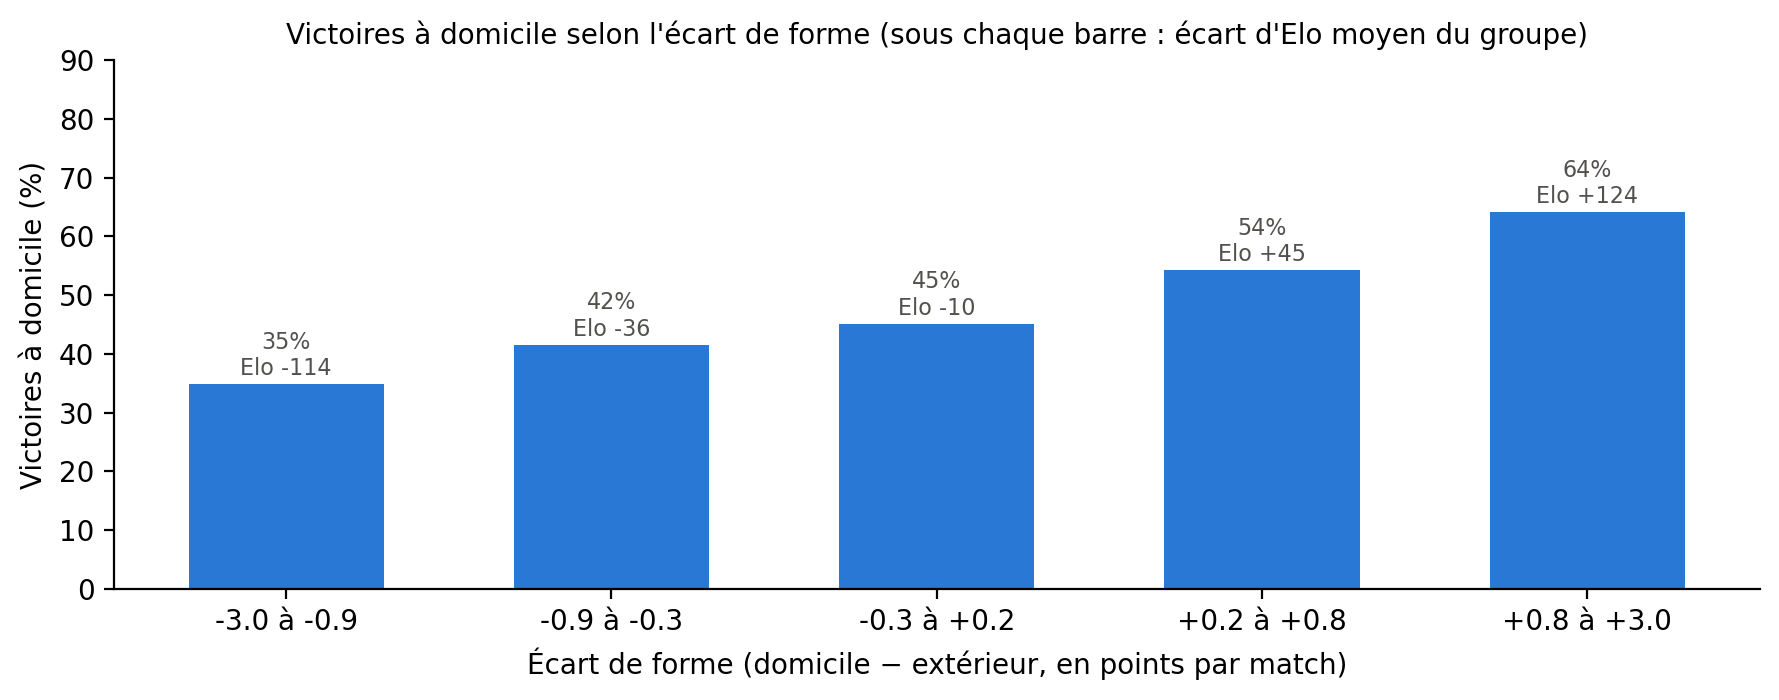

                  matchs  ecart_forme  ecart_elo  victoire_domicile
groupe                                                             
(-3.001, -0.867]     373        -1.38    -114.10               0.35
(-0.867, -0.267]     368        -0.57     -36.09               0.42
(-0.267, 0.2]        394        -0.02      -9.94               0.45
(0.2, 0.8]           363         0.47      45.42               0.54
(0.8, 3.0]           354         1.33     124.12               0.64


In [7]:
# Victoires à domicile selon l'écart de forme, en 5 groupes de même taille
d = etude.dropna(subset=['ecart_forme_5']).copy()
d['groupe'] = pd.qcut(d['ecart_forme_5'], 5, duplicates='drop')
par_groupe = d.groupby('groupe', observed=True).agg(
    matchs=('game_id', 'size'), ecart_forme=('ecart_forme_5', 'mean'), ecart_elo=('ecart_elo_complet', 'mean'),
    victoire_domicile=('resultat', lambda r: (r == 'Victoire domicile').mean()))

fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(par_groupe))
ax.bar(x, par_groupe['victoire_domicile'] * 100, color=BLEU, width=0.6)
for i, (v, e) in enumerate(zip(par_groupe['victoire_domicile'], par_groupe['ecart_elo'])):
    ax.text(i, v * 100 + 1.5, f"{v:.0%}\nElo {e:+.0f}", ha='center', fontsize=8, color=ENCRE)
ax.set_xticks(x, [f"{g.left:+.1f} à {g.right:+.1f}" for g in par_groupe.index])
ax.set_xlabel('Écart de forme (domicile − extérieur, en points par match)')
ax.set_ylabel('Victoires à domicile (%)')
ax.set_ylim(0, 90)
ax.set_title("Victoires à domicile selon l'écart de forme (sous chaque barre : écart d'Elo moyen du groupe)", fontsize=10)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()
print(par_groupe.round(2).to_string())

**Lecture :**

| | Matchs | Forme ~ résultat | Elo ~ résultat | Forme ~ Elo | Forme ~ résultat, Elo retiré |
|---|---|---|---|---|---|
| Tous les matchs | 1 852 | +0,234 | +0,474 | +0,423 | **+0,035** |
| Les deux championnats couverts | 1 558 | +0,183 | +0,439 | +0,347 | **+0,031** |

*Marge à 95 % : environ ± 0,046 sur 1 852 matchs et ± 0,050 sur 1 558 matchs.*

- **On observe un lien entre la forme et le résultat** (+0,23) : sur le graphique, l'équipe qui reçoit gagne **35 %** de ses matchs quand elle est en bien moins bonne forme, et **64 %** quand elle est en bien meilleure forme.
- **Mais la forme suit l'Elo de près** (+0,42) : dans le groupe « bien meilleure forme », l'écart d'Elo moyen est aussi de **+124 points**, contre **−114** dans le groupe opposé. La forme mesure donc en grande partie le niveau du club, ce que l'Elo dit déjà. Et l'Elo est **deux fois plus lié** au résultat que la forme (+0,47 contre +0,23).
- **Une fois l'Elo retiré, il ne reste presque rien** : **+0,035**, en dessous de la marge de hasard (± 0,046). On ne peut pas affirmer que la forme apporte une information en plus de l'Elo.
- **Sur les matchs où les deux championnats sont couverts**, la conclusion est la même (+0,031). Le biais de couverture ne cache donc pas un effet de la forme.
- **Ce qu'on attend du test de `MODEL_POISSON` :** avec une partielle si faible, il est probable que la forme ne fasse pas baisser la log loss de façon nette. C'est une prévision, pas un résultat : le test décidera.

## 6. Export

On n'exporte que les colonnes prévues. Les dates des matchs utilisés ont servi aux contrôles ; elles restent dans le notebook.

In [8]:
sortie = forme[['game_id', 'home_forme_5', 'away_forme_5', 'home_nb_matchs_forme', 'away_nb_matchs_forme', 'ecart_forme_5']].copy()
sortie[['home_nb_matchs_forme', 'away_nb_matchs_forme']] = sortie[['home_nb_matchs_forme', 'away_nb_matchs_forme']].astype(int)

assert len(sortie) == 1871 and sortie['game_id'].is_unique
assert set(sortie['game_id']) == set(c1['game_id']), "Mêmes matchs que eda_matchs_c1.csv"
assert ((sortie['home_forme_5'] - sortie['away_forme_5']).sub(sortie['ecart_forme_5']).abs().fillna(0) < 1e-12).all()

sortie.to_csv('../output/forme_par_match.csv', index=False, encoding='utf-8-sig')
print(f"output/forme_par_match.csv : {len(sortie):,} lignes, {sortie.shape[1]} colonnes")
sortie.head()

output/forme_par_match.csv : 1,871 lignes, 6 colonnes


,game_id,home_forme_5,away_forme_5,home_nb_matchs_forme,away_nb_matchs_forme,ecart_forme_5
0,2262147,3.0,2.5,5,4,0.5
1,2262148,1.8,1.8,5,5,0.0
2,2262149,0.8,2.0,5,4,-1.2
3,2262150,3.0,2.5,3,4,0.5
4,2262151,2.2,1.4,5,5,0.8


**Lecture :** `output/forme_par_match.csv` contient **1 871 lignes**, une par match de C1, exactement les mêmes `game_id` que `eda_matchs_c1.csv`, et 6 colonnes.

## 7. Limites et conclusion

**Ce qu'on a construit :** une forme récente **sans fuite** (5 derniers matchs officiels, strictement avant le match, dans les 60 jours), corrigée des **1 221 scores** qui incluaient des tirs au but, et disponible pour **99 %** des matchs.

**Ce qu'on observe :** la forme est liée au résultat (+0,23), mais surtout parce qu'elle suit le niveau du club (+0,42 avec l'Elo). Une fois l'Elo retiré, son lien avec le résultat (+0,035) ne se distingue pas du hasard. **Elle risque donc de ne rien apporter au modèle**, et c'est au test de `MODEL_POISSON` de trancher.

**Limites :**
- **La force des adversaires n'est pas prise en compte** : 3 victoires contre des promus valent autant que 3 victoires contre des grands clubs. L'Elo, lui, en tient compte.
- **Couverture inégale** : pour les clubs dont le championnat manque dans `games.csv` (Salzbourg, Dinamo Zagreb, Bâle…), les 5 matchs sont surtout des matchs de coupe ou d'Europe. Le résultat ne change presque pas quand on les retire, mais leur forme veut dire autre chose.
- **Début de saison** : 11 % des lignes ont moins de 5 matchs, et la moyenne y est plus instable (une seule défaite pèse plus).
- **Les réglages (5 matchs, 60 jours) ont été fixés avant de voir les résultats**, et on ne les a pas modifiés après. En essayer plusieurs pour garder celui qui « marche » le mieux reviendrait à ajuster la variable sur les résultats qu'on veut prédire.